# Generate UMAP for the heart failure subtyping plates (QC'd feature selected profiles)

All plates in the run are combined and embedded together using the features shared across plates.
Set `hlhs_run = True` to use the HLHS plates instead of the default subtyping plates.

In [1]:
import argparse
import pathlib
import sys

import pandas as pd
import umap
from plotnine import (
    aes,
    element_text,
    facet_wrap,
    geom_point,
    ggplot,
    guide_legend,
    guides,
    labs,
    scale_color_gradient2,
    scale_color_manual,
    theme,
    theme_bw,
)
from plotnine.options import set_option
from pycytominer.cyto_utils import infer_cp_features


In [2]:
# Optional CLI fallback for direct script-style execution.
def _str_to_bool(value: str) -> bool:
    """
    Convert a string to a boolean value.

    Args:
        value (str): The string to convert.

    Returns:
        bool: True if the string represents a true value, False otherwise.
    """
    return str(value).strip().lower() in ("1", "true", "yes")


In [3]:
# Set if this run is for the HLHS plates (will be updated by papermill)
hlhs_run = True

parser = argparse.ArgumentParser(add_help=False)
parser.add_argument(
    "--hlhs-run", dest="hlhs_run", type=_str_to_bool, default=hlhs_run
)
args, _ = parser.parse_known_args(sys.argv[1:])
hlhs_run = args.hlhs_run


In [4]:
# Set constants
umap_random_seed = 0
umap_n_components = 2

# Directory with the single-cell profiles and figure directory
# (HLHS plates are in a subfolder of the default subtyping plates)
if hlhs_run:
    data_dir = pathlib.Path("../3.preprocessing_profiles/data/single_cell_profiles/hlhs")
    figure_dir = pathlib.Path("figures/umaps/hlhs_plates")
else:
    data_dir = pathlib.Path("../3.preprocessing_profiles/data/single_cell_profiles/")
    figure_dir = pathlib.Path("figures/umaps/subtyping_plates")
figure_dir.mkdir(parents=True, exist_ok=True)

# Figure directory for the UMAPs generated per plate
per_plate_figure_dir = figure_dir / "per_plate"
per_plate_figure_dir.mkdir(parents=True, exist_ok=True)

# Columns that uniquely identify a single cell
cell_id_cols = [
    "Metadata_Plate",
    "Metadata_Well",
    "Metadata_Site",
    "Metadata_Nuclei_Number_Object_Number",
]

# Colorblind-friendly palette for the heart failure types
failure_type_colors = {
    "Healthy": "#009E73",
    "DCM": "#0072B2",
    "ICM": "#E69F00",
}
if hlhs_run:
    failure_type_colors["HLHS"] = "#CC79A7"


In [5]:
# Load in the QC feature selected profiles for all plates in the run
fs_paths = sorted(data_dir.glob("*_sc_feature_selected.parquet"))
if not fs_paths:
    raise FileNotFoundError(f"No feature selected parquet files found in {data_dir}")

plate_dfs = []
for path in fs_paths:
    plate_df = pd.read_parquet(path)
    print(f"{path.name}: {plate_df.shape}")
    plate_dfs.append(plate_df)

# Feature selection is performed per plate, so only keep the columns shared across all plates
qc_df = pd.concat(plate_dfs, join="inner", ignore_index=True)

print(f"Combined QC dataset shape: {qc_df.shape}")
print(f"Number of shared CellProfiler features: {len(infer_cp_features(qc_df))}")
print(qc_df["Metadata_Plate"].value_counts())


CARD-CelIns-CX7_260407120001_sc_feature_selected.parquet: (10612, 1078)
CARD-CelIns-CX7_260407190001_sc_feature_selected.parquet: (14919, 1000)
Combined QC dataset shape: (25531, 858)
Number of shared CellProfiler features: 804
Metadata_Plate
CARD-CelIns-CX7_260407190001    14919
CARD-CelIns-CX7_260407120001    10612
Name: count, dtype: int64


In [6]:
# Actin max intensity can be removed during feature selection, so load it from the
# normalized profiles and add Metadata_ prefix to use in UMAP plot later
actin_df = pd.concat(
    [
        pd.read_parquet(
            pathlib.Path(str(path).replace("_sc_feature_selected", "_sc_normalized")),
            columns=cell_id_cols + ["Cells_Intensity_MaxIntensity_Actin"],
        )
        for path in fs_paths
    ],
    ignore_index=True,
).rename(
    columns={
        "Cells_Intensity_MaxIntensity_Actin": "Metadata_Cells_Intensity_MaxIntensity_Actin"
    }
)

qc_df = qc_df.merge(actin_df, on=cell_id_cols, how="left", validate="one_to_one")
assert qc_df["Metadata_Cells_Intensity_MaxIntensity_Actin"].notna().all()

# Healthy hearts have no heart failure type, so label them as Healthy
qc_df["Metadata_heart_failure_type"] = pd.Categorical(
    qc_df["Metadata_heart_failure_type"].fillna("Healthy"),
    categories=list(failure_type_colors),
    ordered=True,
)

# Create a facet label that includes "Heart #" and order by failure type then heart
qc_df["Metadata_heart_number"] = qc_df["Metadata_heart_number"].astype(str)
qc_df["Metadata_heart_number_label"] = "Heart #" + qc_df["Metadata_heart_number"]
heart_order = (
    qc_df[["Metadata_heart_failure_type", "Metadata_heart_number"]]
    .drop_duplicates()
    .assign(
        heart_sort=lambda df: pd.to_numeric(
            df["Metadata_heart_number"], errors="coerce"
        )
    )
    .sort_values(["Metadata_heart_failure_type", "heart_sort", "Metadata_heart_number"])
)
qc_df["Metadata_heart_number_label"] = pd.Categorical(
    qc_df["Metadata_heart_number_label"],
    categories=("Heart #" + heart_order["Metadata_heart_number"]).tolist(),
    ordered=True,
)

print(
    qc_df.groupby(
        ["Metadata_heart_failure_type", "Metadata_heart_number", "Metadata_Plate"],
        observed=True,
    )
    .size()
    .unstack("Metadata_Plate")
)


Metadata_Plate                                     CARD-CelIns-CX7_260407120001  \
Metadata_heart_failure_type Metadata_heart_number                                 
Healthy                     2                                               811   
                            38                                              222   
                            7                                               700   
DCM                         23                                              789   
                            36                                              940   
                            50                                              604   
ICM                         30                                              813   
                            44                                              687   
                            51                                              871   
HLHS                        A                                              1833   
    

/tmp/ipykernel_1435377/450150084.py:30: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`


## UMAP with QC profiles (all plates in the run)

In [7]:
# Process cp_df to separate features and metadata
cp_features = infer_cp_features(qc_df)
meta_features = infer_cp_features(qc_df, metadata=True)

# Initialize UMAP instance
umap_fit = umap.UMAP(
    random_state=umap_random_seed, n_components=umap_n_components, n_jobs=1
)

# Fit UMAP and convert to pandas DataFrame
embeddings = pd.DataFrame(
    umap_fit.fit_transform(qc_df.loc[:, cp_features]),
    columns=[f"UMAP{x}" for x in range(0, umap_n_components)],
    index=qc_df.index,  # ✅ ensures alignment
)
print(f"{embeddings.shape} UMAP embeddings generated")

# Combine with metadata
cp_umap_with_metadata_qc_df = pd.concat(
    [qc_df.loc[:, meta_features], embeddings], axis=1
)

# Shuffle the rows so no single plate or heart is always plotted on top
cp_umap_with_metadata_qc_df = cp_umap_with_metadata_qc_df.sample(
    frac=1, random_state=umap_random_seed
)


(25531, 2) UMAP embeddings generated


/home/jenna/mambaforge/envs/fibrosis_eda_env/lib/python3.10/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 8 x 8 in image.
/home/jenna/mambaforge/envs/fibrosis_eda_env/lib/python3.10/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: figures/umaps/hlhs_plates/umap_with_QC_by_plate.png


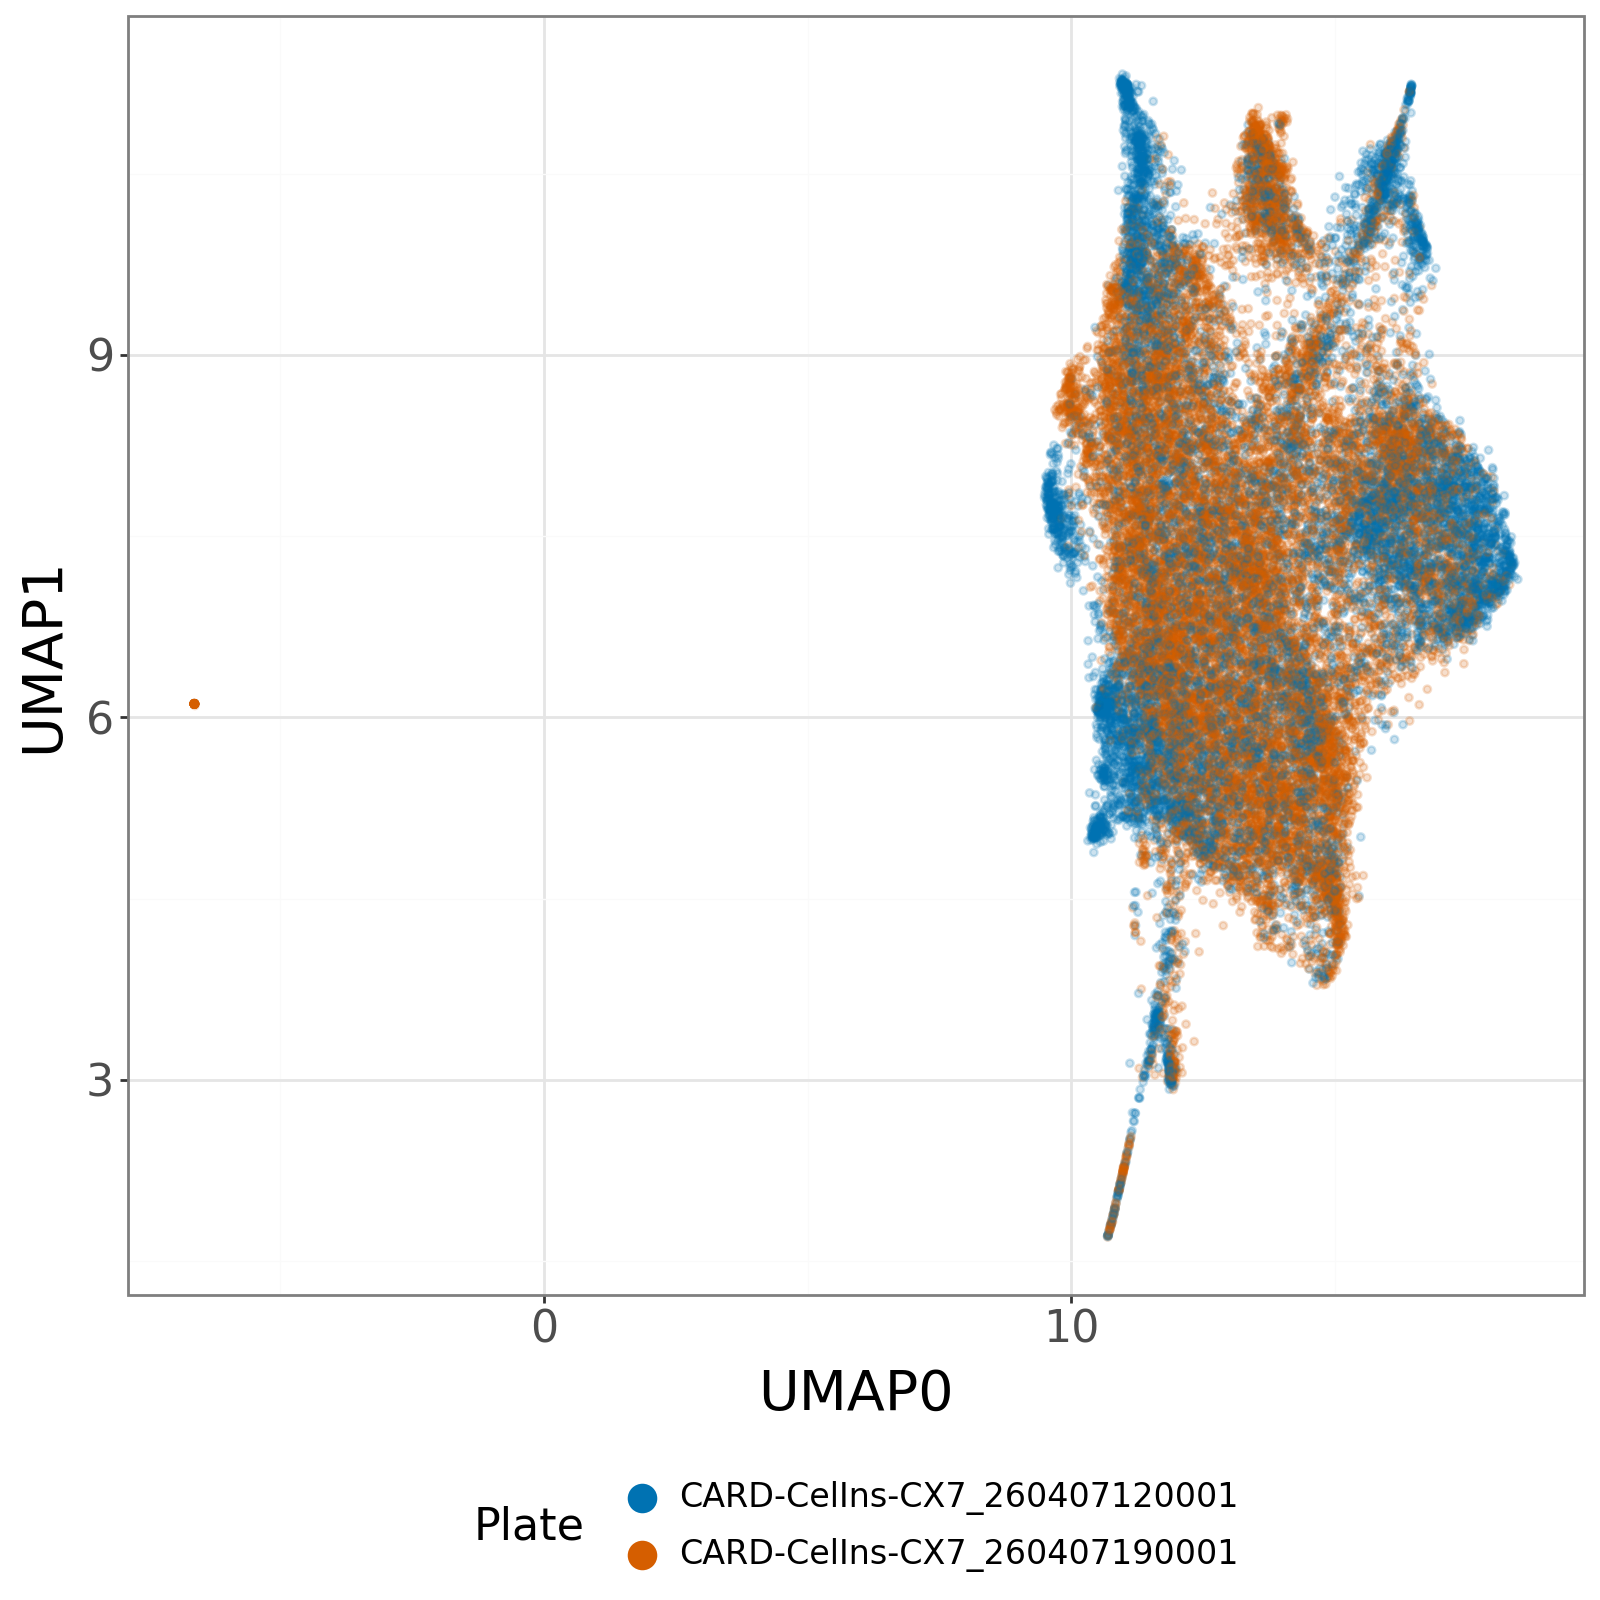

In [8]:
# Set the figure size
height = 8
width = 8
set_option("figure_size", (width, height))

# Plot UMAP of QC profiles colored by plate to check for plate effects
p = (
    ggplot(
        cp_umap_with_metadata_qc_df,
        aes(x="UMAP0", y="UMAP1", color="Metadata_Plate"),
    )
    + labs(
        color="Plate",
    )
    + geom_point(alpha=0.2, size=1)
    + theme_bw()
    + theme(
        axis_title=element_text(size=20),
        axis_text=element_text(size=16),
        legend_title=element_text(size=16),
        legend_text=element_text(size=12),
        legend_position="bottom",
    )
    + scale_color_manual(values=["#0072B2", "#D55E00", "#009E73"])
    + guides(
        color=guide_legend(
            ncol=1,
            override_aes={
                "alpha": 1,  # fully opaque in legend
                "size": 5,  # bigger points in legend
            },
        )
    )
)
# Save the plot
p.save(figure_dir / "umap_with_QC_by_plate.png", dpi=600, width=width, height=height)

p.show()


/home/jenna/mambaforge/envs/fibrosis_eda_env/lib/python3.10/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 8 x 8 in image.
/home/jenna/mambaforge/envs/fibrosis_eda_env/lib/python3.10/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: figures/umaps/hlhs_plates/umap_with_QC_by_failure_type.png


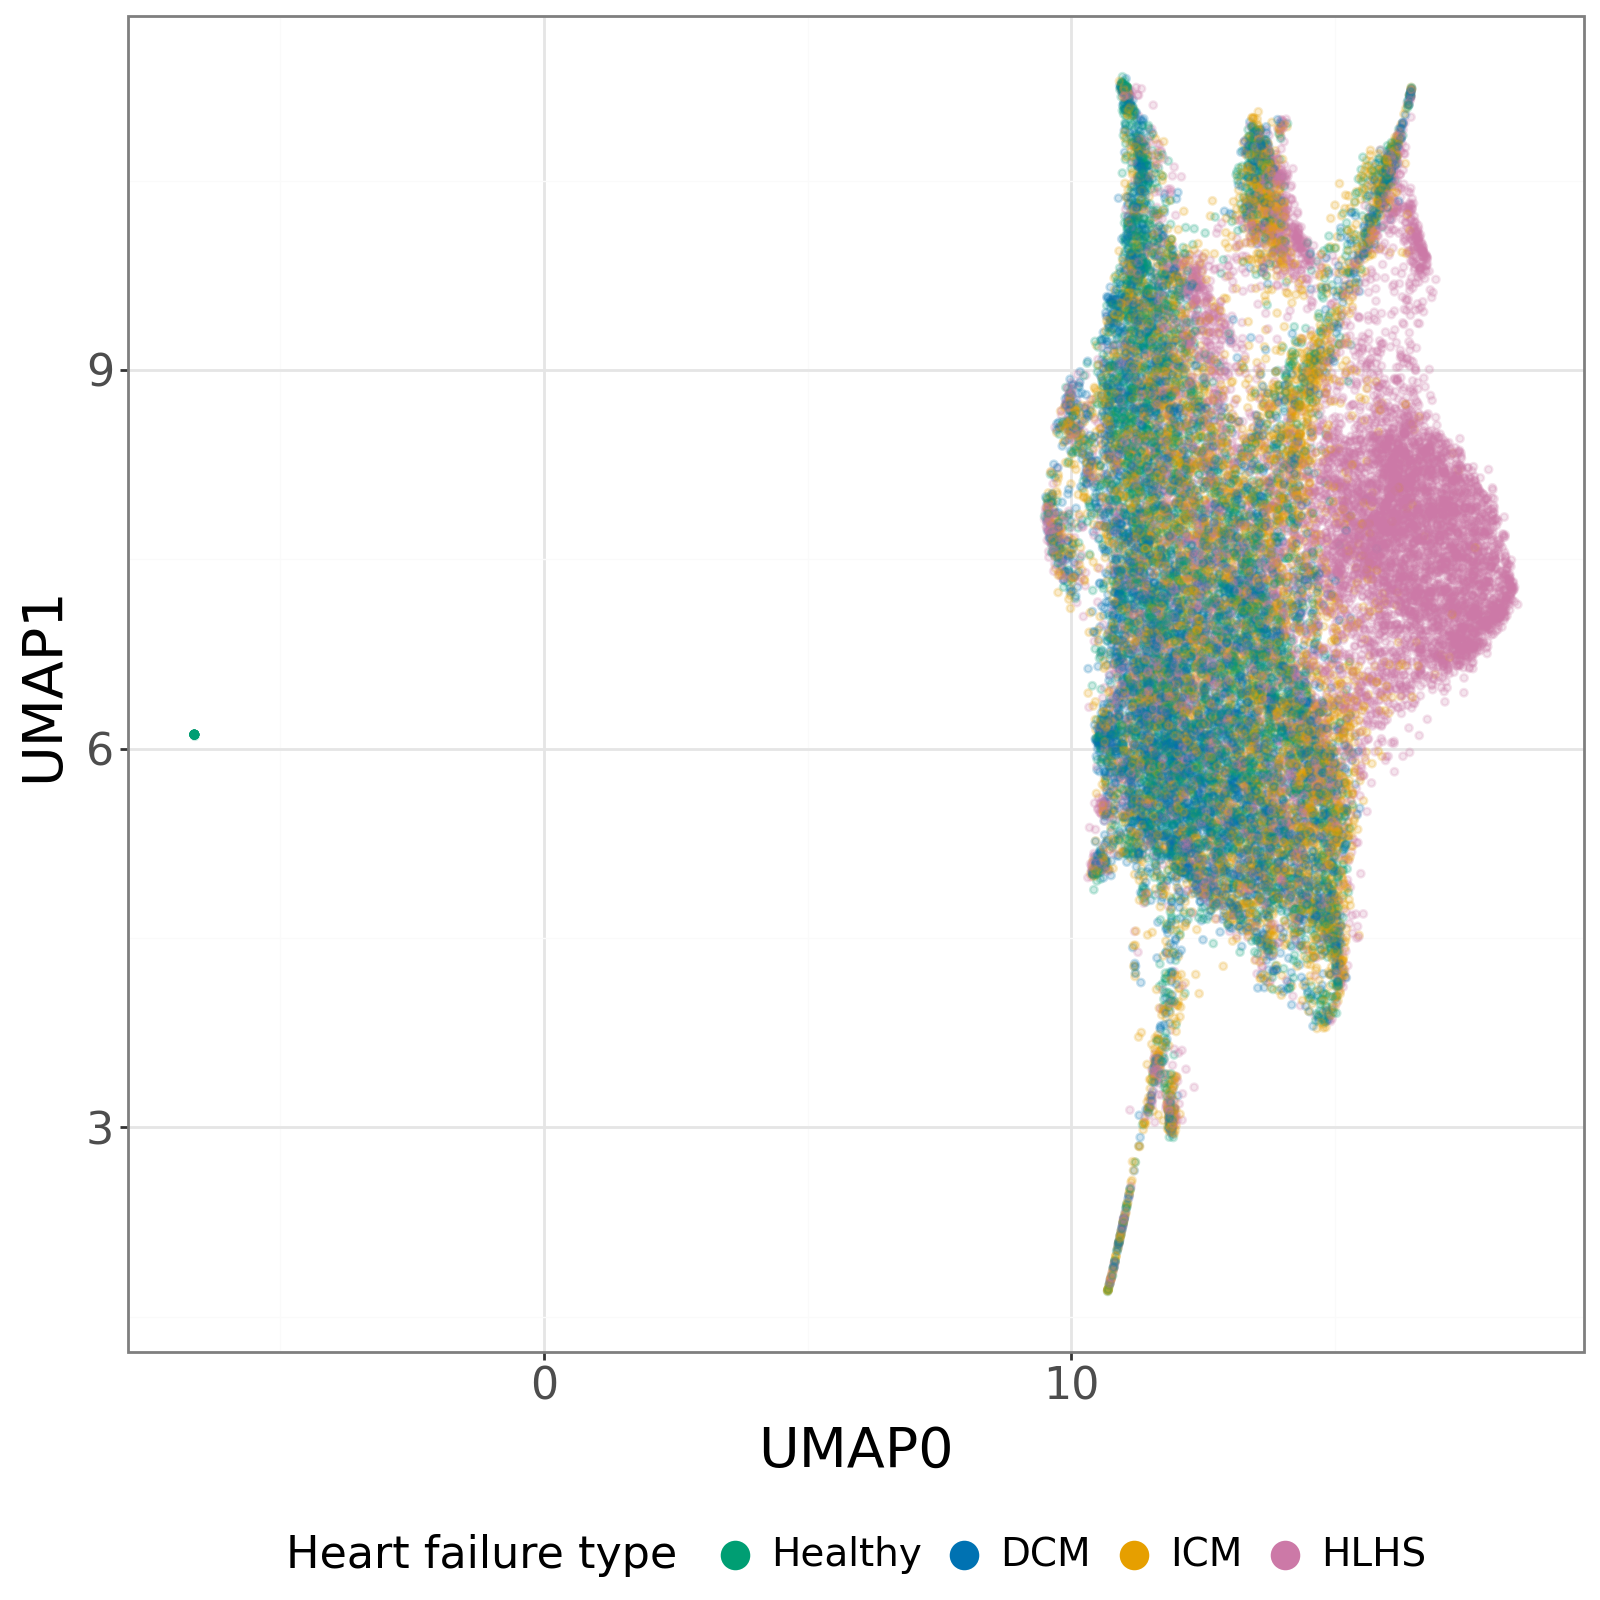

In [9]:
# Set the figure size
height = 8
width = 8
set_option("figure_size", (width, height))

# Plot UMAP of QC profiles colored by heart failure type
p = (
    ggplot(
        cp_umap_with_metadata_qc_df,
        aes(x="UMAP0", y="UMAP1", color="Metadata_heart_failure_type"),
    )
    + labs(
        color="Heart failure type",
    )
    + geom_point(alpha=0.2, size=1)
    + theme_bw()
    + theme(
        axis_title=element_text(size=20),
        axis_text=element_text(size=16),
        legend_title=element_text(size=16),
        legend_text=element_text(size=14),
        legend_position="bottom",
    )
    + scale_color_manual(values=failure_type_colors)
    + guides(
        color=guide_legend(
            override_aes={
                "alpha": 1,  # fully opaque in legend
                "size": 5,  # bigger points in legend
            }
        )
    )
)
# Save the plot
p.save(
    figure_dir / "umap_with_QC_by_failure_type.png",
    dpi=600,
    width=width,
    height=height,
)

p.show()


/home/jenna/mambaforge/envs/fibrosis_eda_env/lib/python3.10/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 12 x 10 in image.
/home/jenna/mambaforge/envs/fibrosis_eda_env/lib/python3.10/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: figures/umaps/hlhs_plates/facet_umap_with_QC_by_failure_type.png


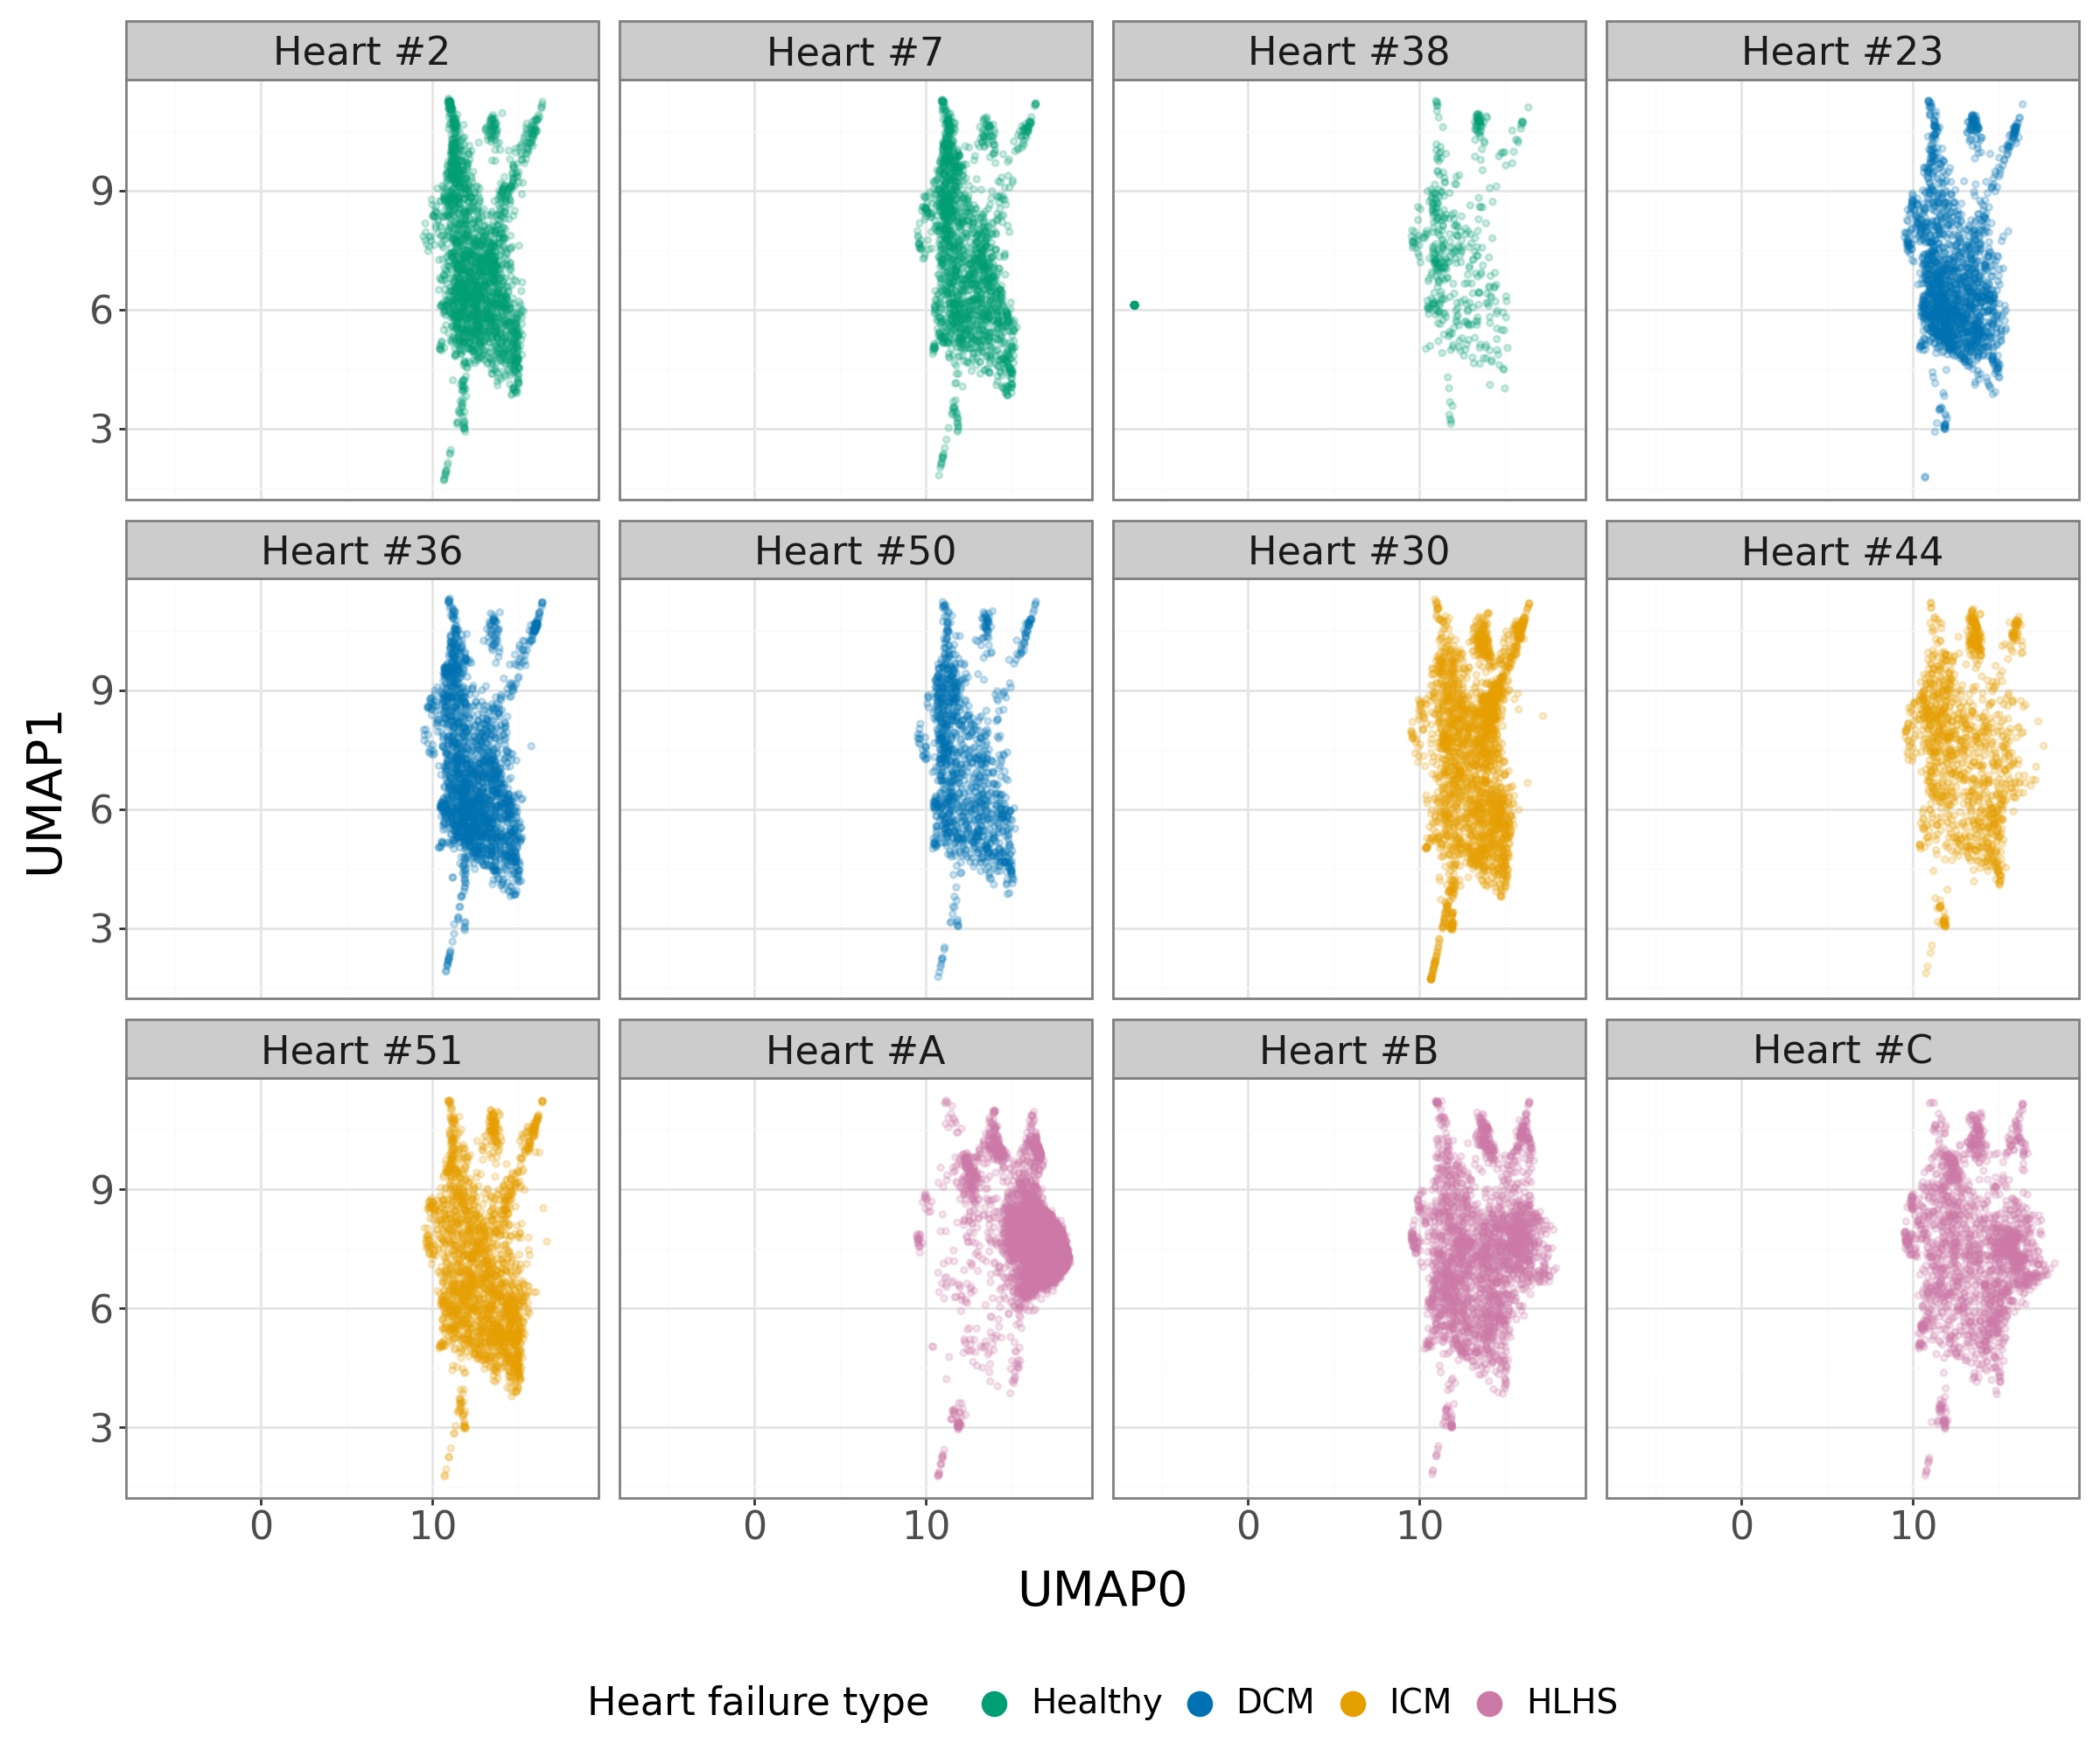

In [10]:
# Set the figure size
height = 10
width = 12
set_option("figure_size", (width, height))

# Plot UMAP of QC profiles colored by heart failure type and faceted by heart number
p = (
    ggplot(
        cp_umap_with_metadata_qc_df,
        aes(x="UMAP0", y="UMAP1", color="Metadata_heart_failure_type"),
    )
    + labs(
        color="Heart failure type",
    )
    + geom_point(alpha=0.2, size=1)
    + facet_wrap(
        "Metadata_heart_number_label",
        ncol=4,
        scales="fixed",
    )
    + theme_bw()
    + theme(
        axis_title=element_text(size=20),
        axis_text=element_text(size=16),
        legend_title=element_text(size=16),
        legend_text=element_text(size=14),
        legend_position="bottom",
        strip_text=element_text(size=16),  # Adjust facet label size
    )
    + scale_color_manual(values=failure_type_colors)
    + guides(
        color=guide_legend(
            override_aes={
                "alpha": 1,  # fully opaque in legend
                "size": 5,  # bigger points in legend
            }
        )
    )
)
# Save the plot
p.save(
    figure_dir / "facet_umap_with_QC_by_failure_type.png",
    dpi=600,
    width=width,
    height=height,
)

p.show()


/home/jenna/mambaforge/envs/fibrosis_eda_env/lib/python3.10/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 12 x 10 in image.
/home/jenna/mambaforge/envs/fibrosis_eda_env/lib/python3.10/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: figures/umaps/hlhs_plates/facet_umap_with_QC_plot.png


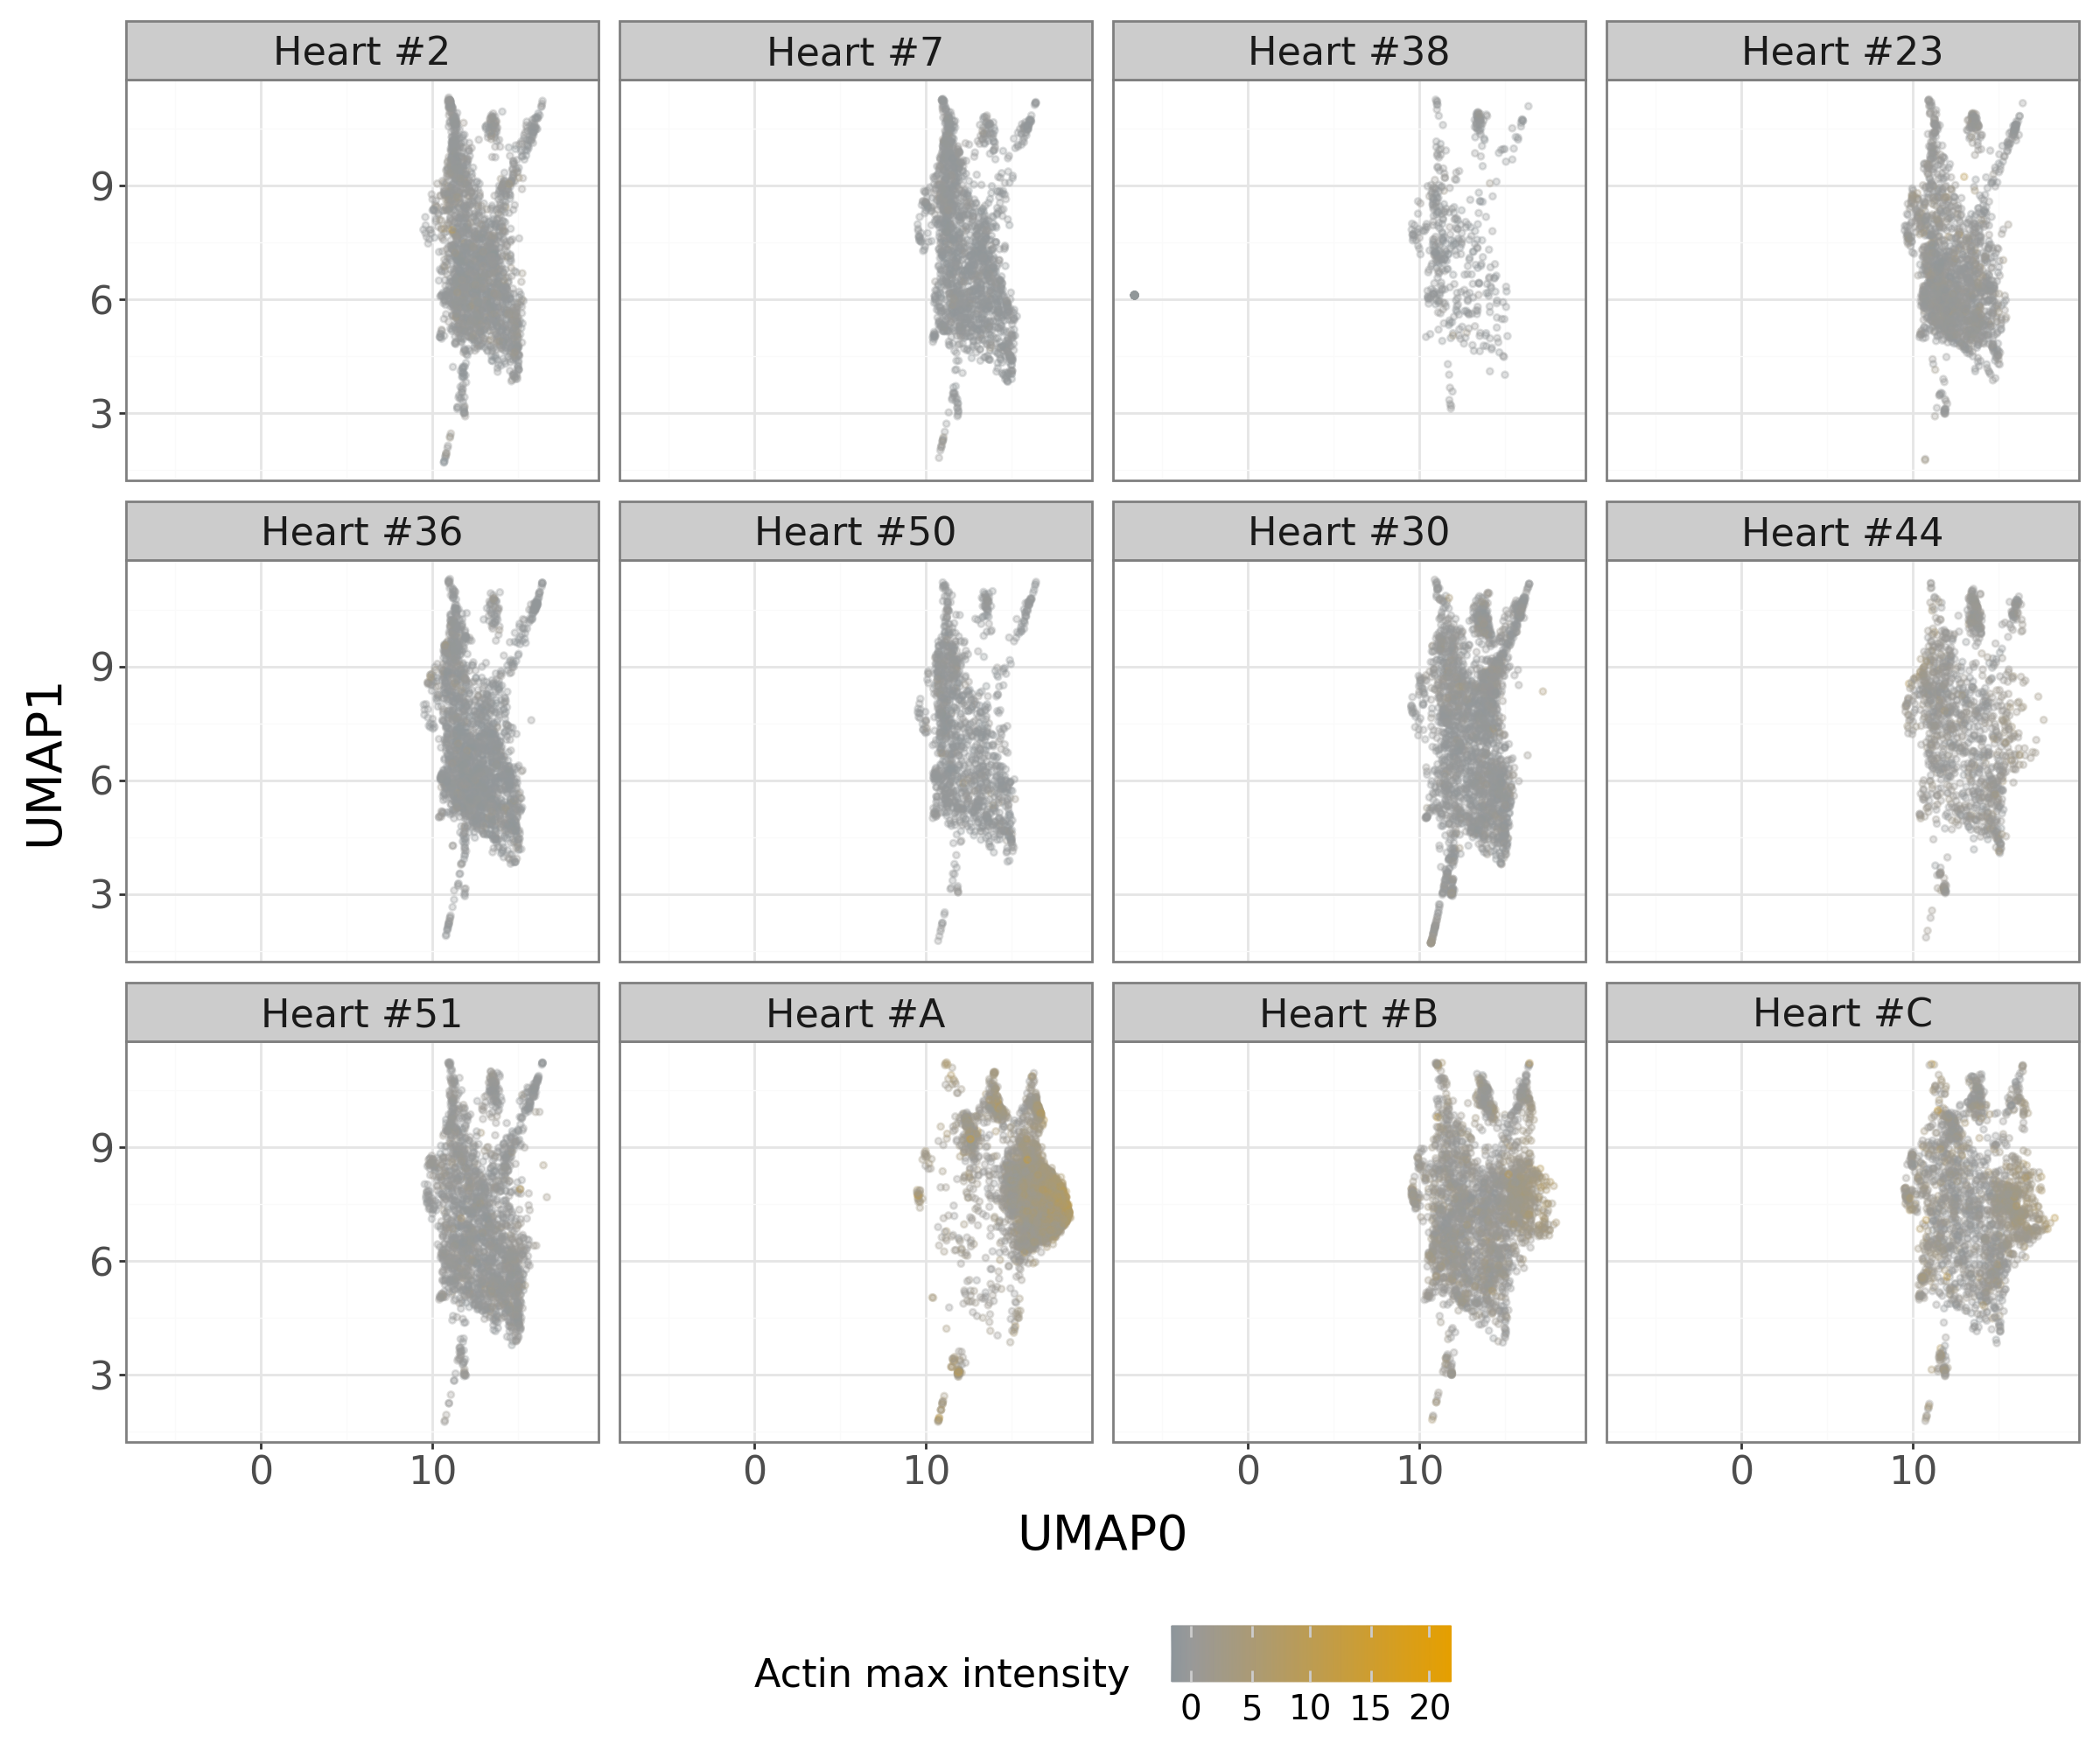

In [11]:
# Set the figure size
height = 10
width = 12
set_option("figure_size", (width, height))

# Plot UMAP of QC profiles colored by actin max intensity and faceted by heart number
p = (
    ggplot(
        cp_umap_with_metadata_qc_df,
        aes(x="UMAP0", y="UMAP1", color="Metadata_Cells_Intensity_MaxIntensity_Actin"),
    )
    + labs(
        color="Actin max intensity",
    )
    + geom_point(alpha=0.3, size=1)
    + facet_wrap(
        "Metadata_heart_number_label",
        ncol=4,
        scales="fixed",
    )
    + theme_bw()
    + theme(
        axis_title=element_text(size=20),
        axis_text=element_text(size=16),
        legend_title=element_text(size=16),
        legend_text=element_text(size=14),
        legend_position="bottom",
        strip_text=element_text(size=16),
    )
    + scale_color_gradient2(low="#0072B2", mid="#999999", high="#E69F00", midpoint=0)
)
# Save the plot
p.save(
    figure_dir / "facet_umap_with_QC_plot.png",
    dpi=600,
    width=width,
    height=height,
)

p.show()


## UMAP per plate

Each plate is embedded on its own using that plate's feature selected features.

CARD-CelIns-CX7_260407120001: (10612, 2) UMAP embeddings generated


/home/jenna/mambaforge/envs/fibrosis_eda_env/lib/python3.10/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 12 x 10 in image.
/home/jenna/mambaforge/envs/fibrosis_eda_env/lib/python3.10/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: figures/umaps/hlhs_plates/per_plate/CARD-CelIns-CX7_260407120001_facet_umap_by_failure_type.png


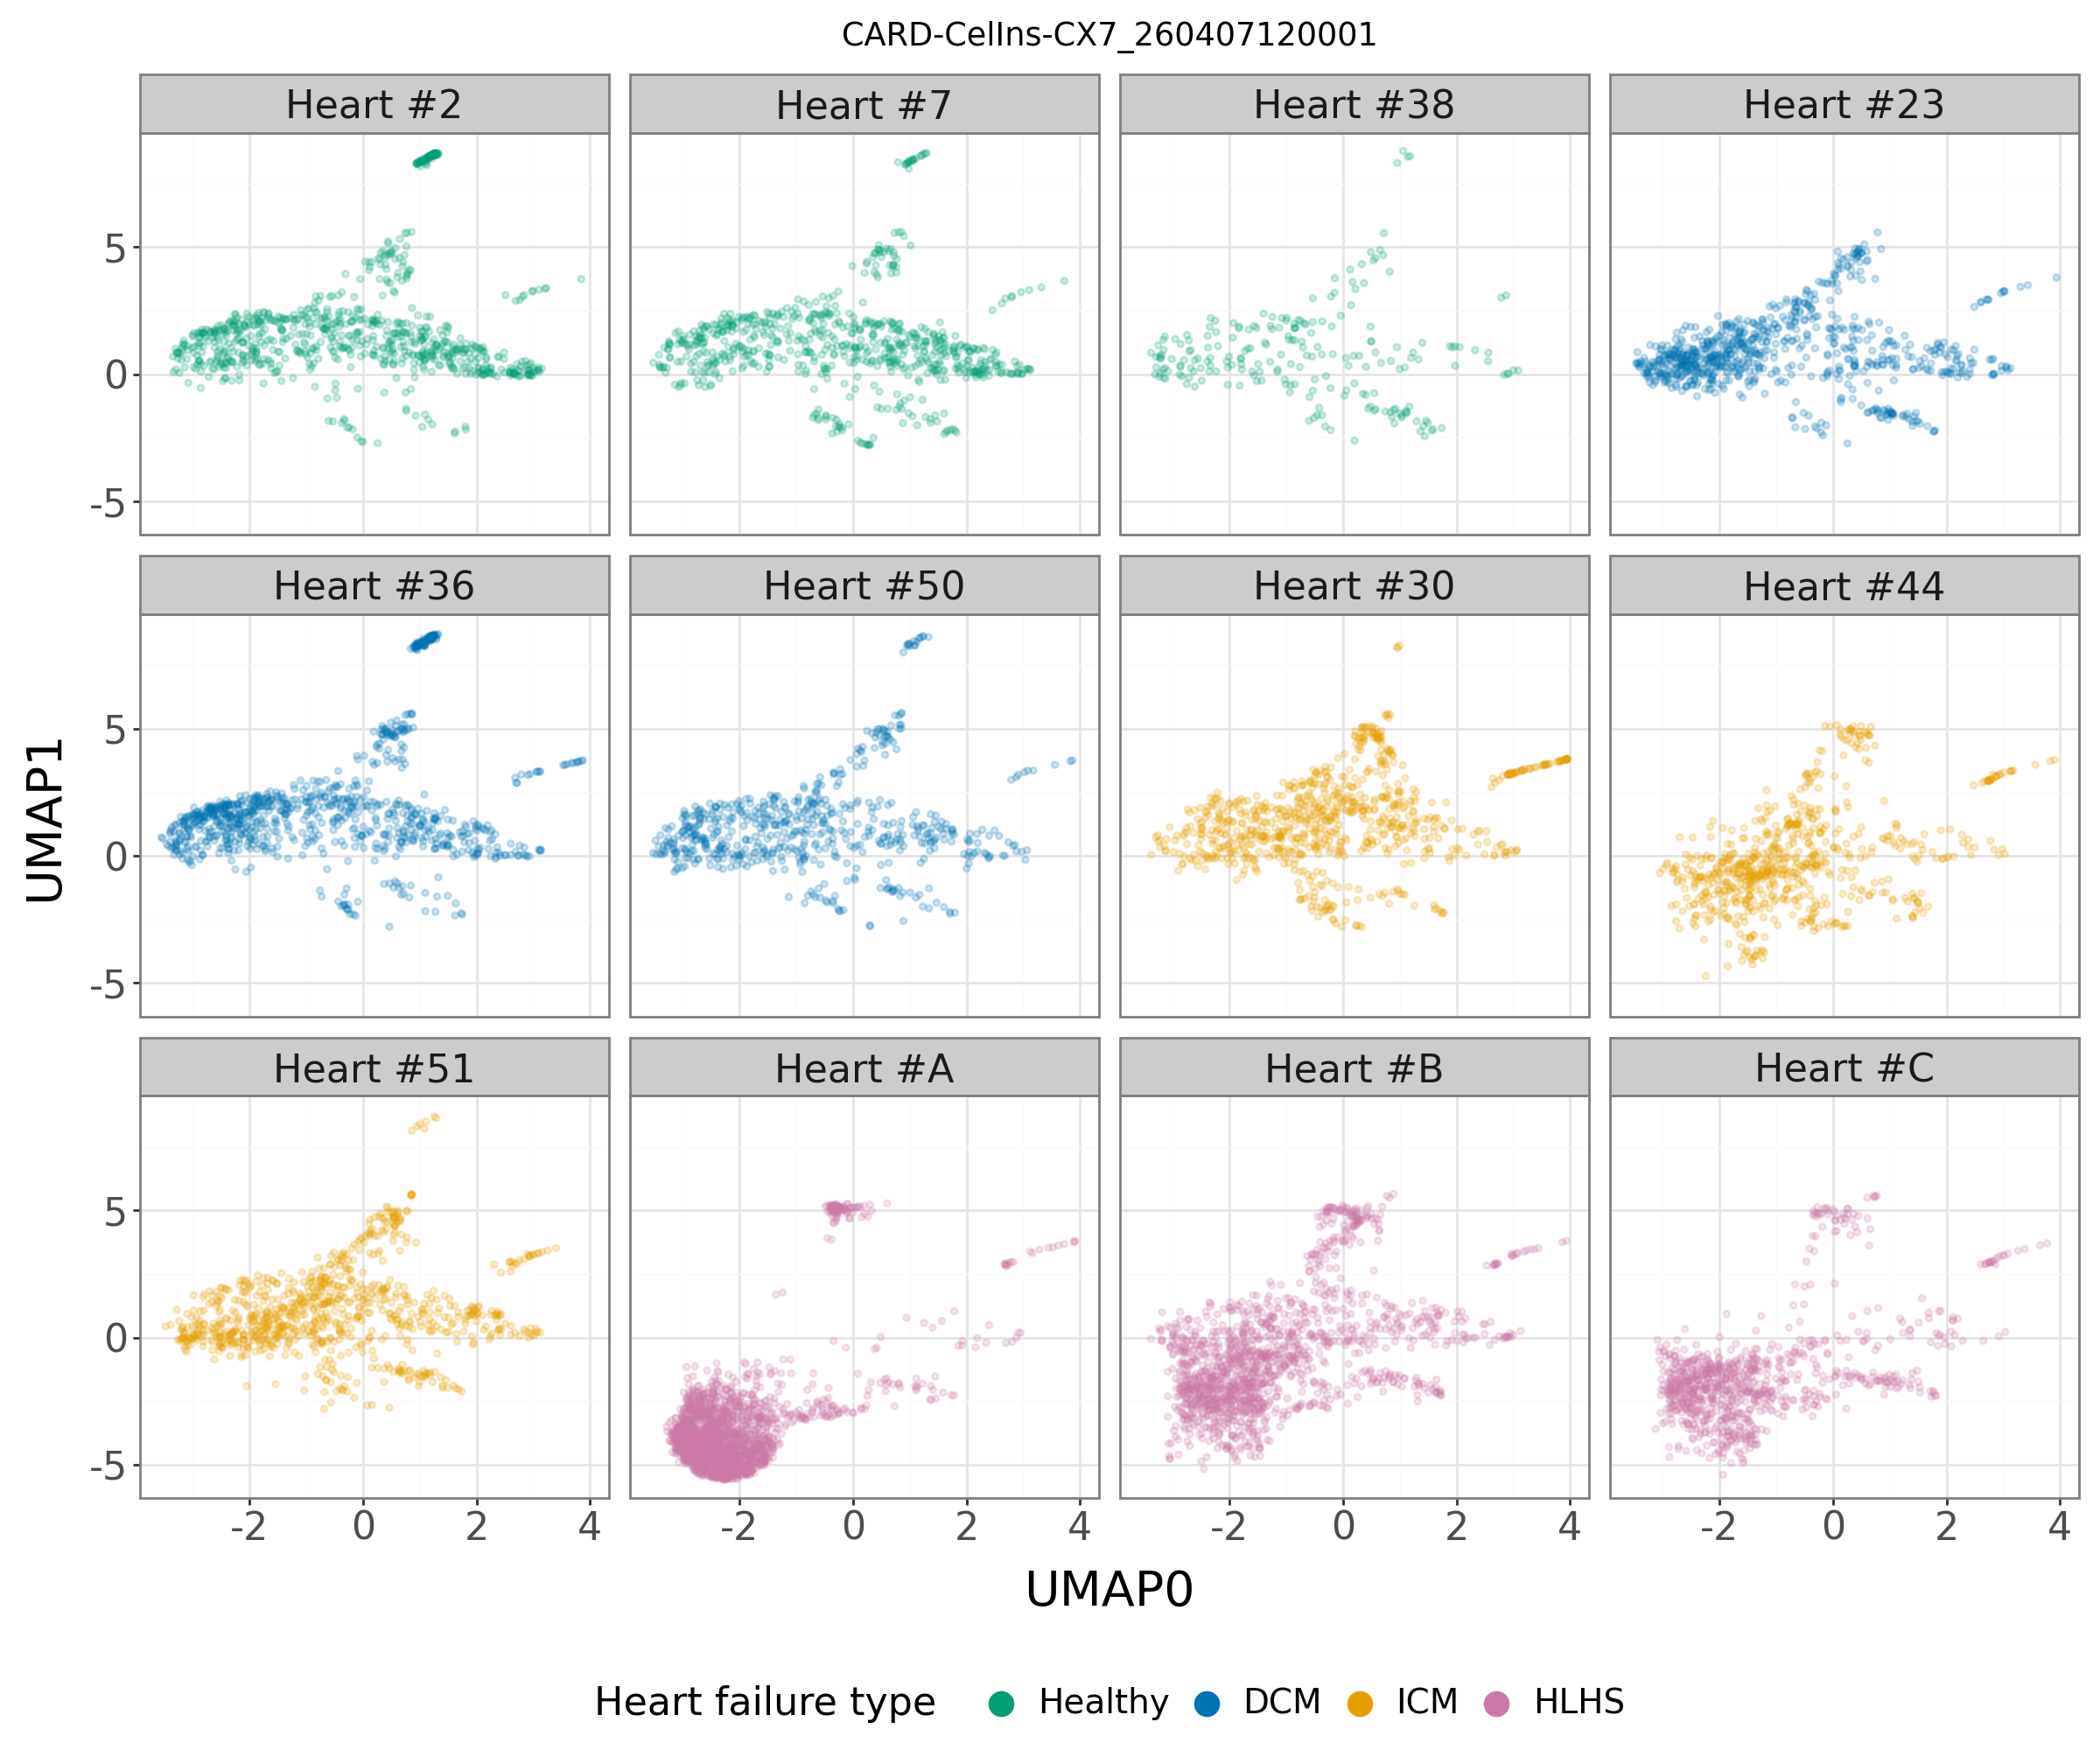

CARD-CelIns-CX7_260407190001: (14919, 2) UMAP embeddings generated


/home/jenna/mambaforge/envs/fibrosis_eda_env/lib/python3.10/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 12 x 10 in image.
/home/jenna/mambaforge/envs/fibrosis_eda_env/lib/python3.10/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: figures/umaps/hlhs_plates/per_plate/CARD-CelIns-CX7_260407190001_facet_umap_by_failure_type.png


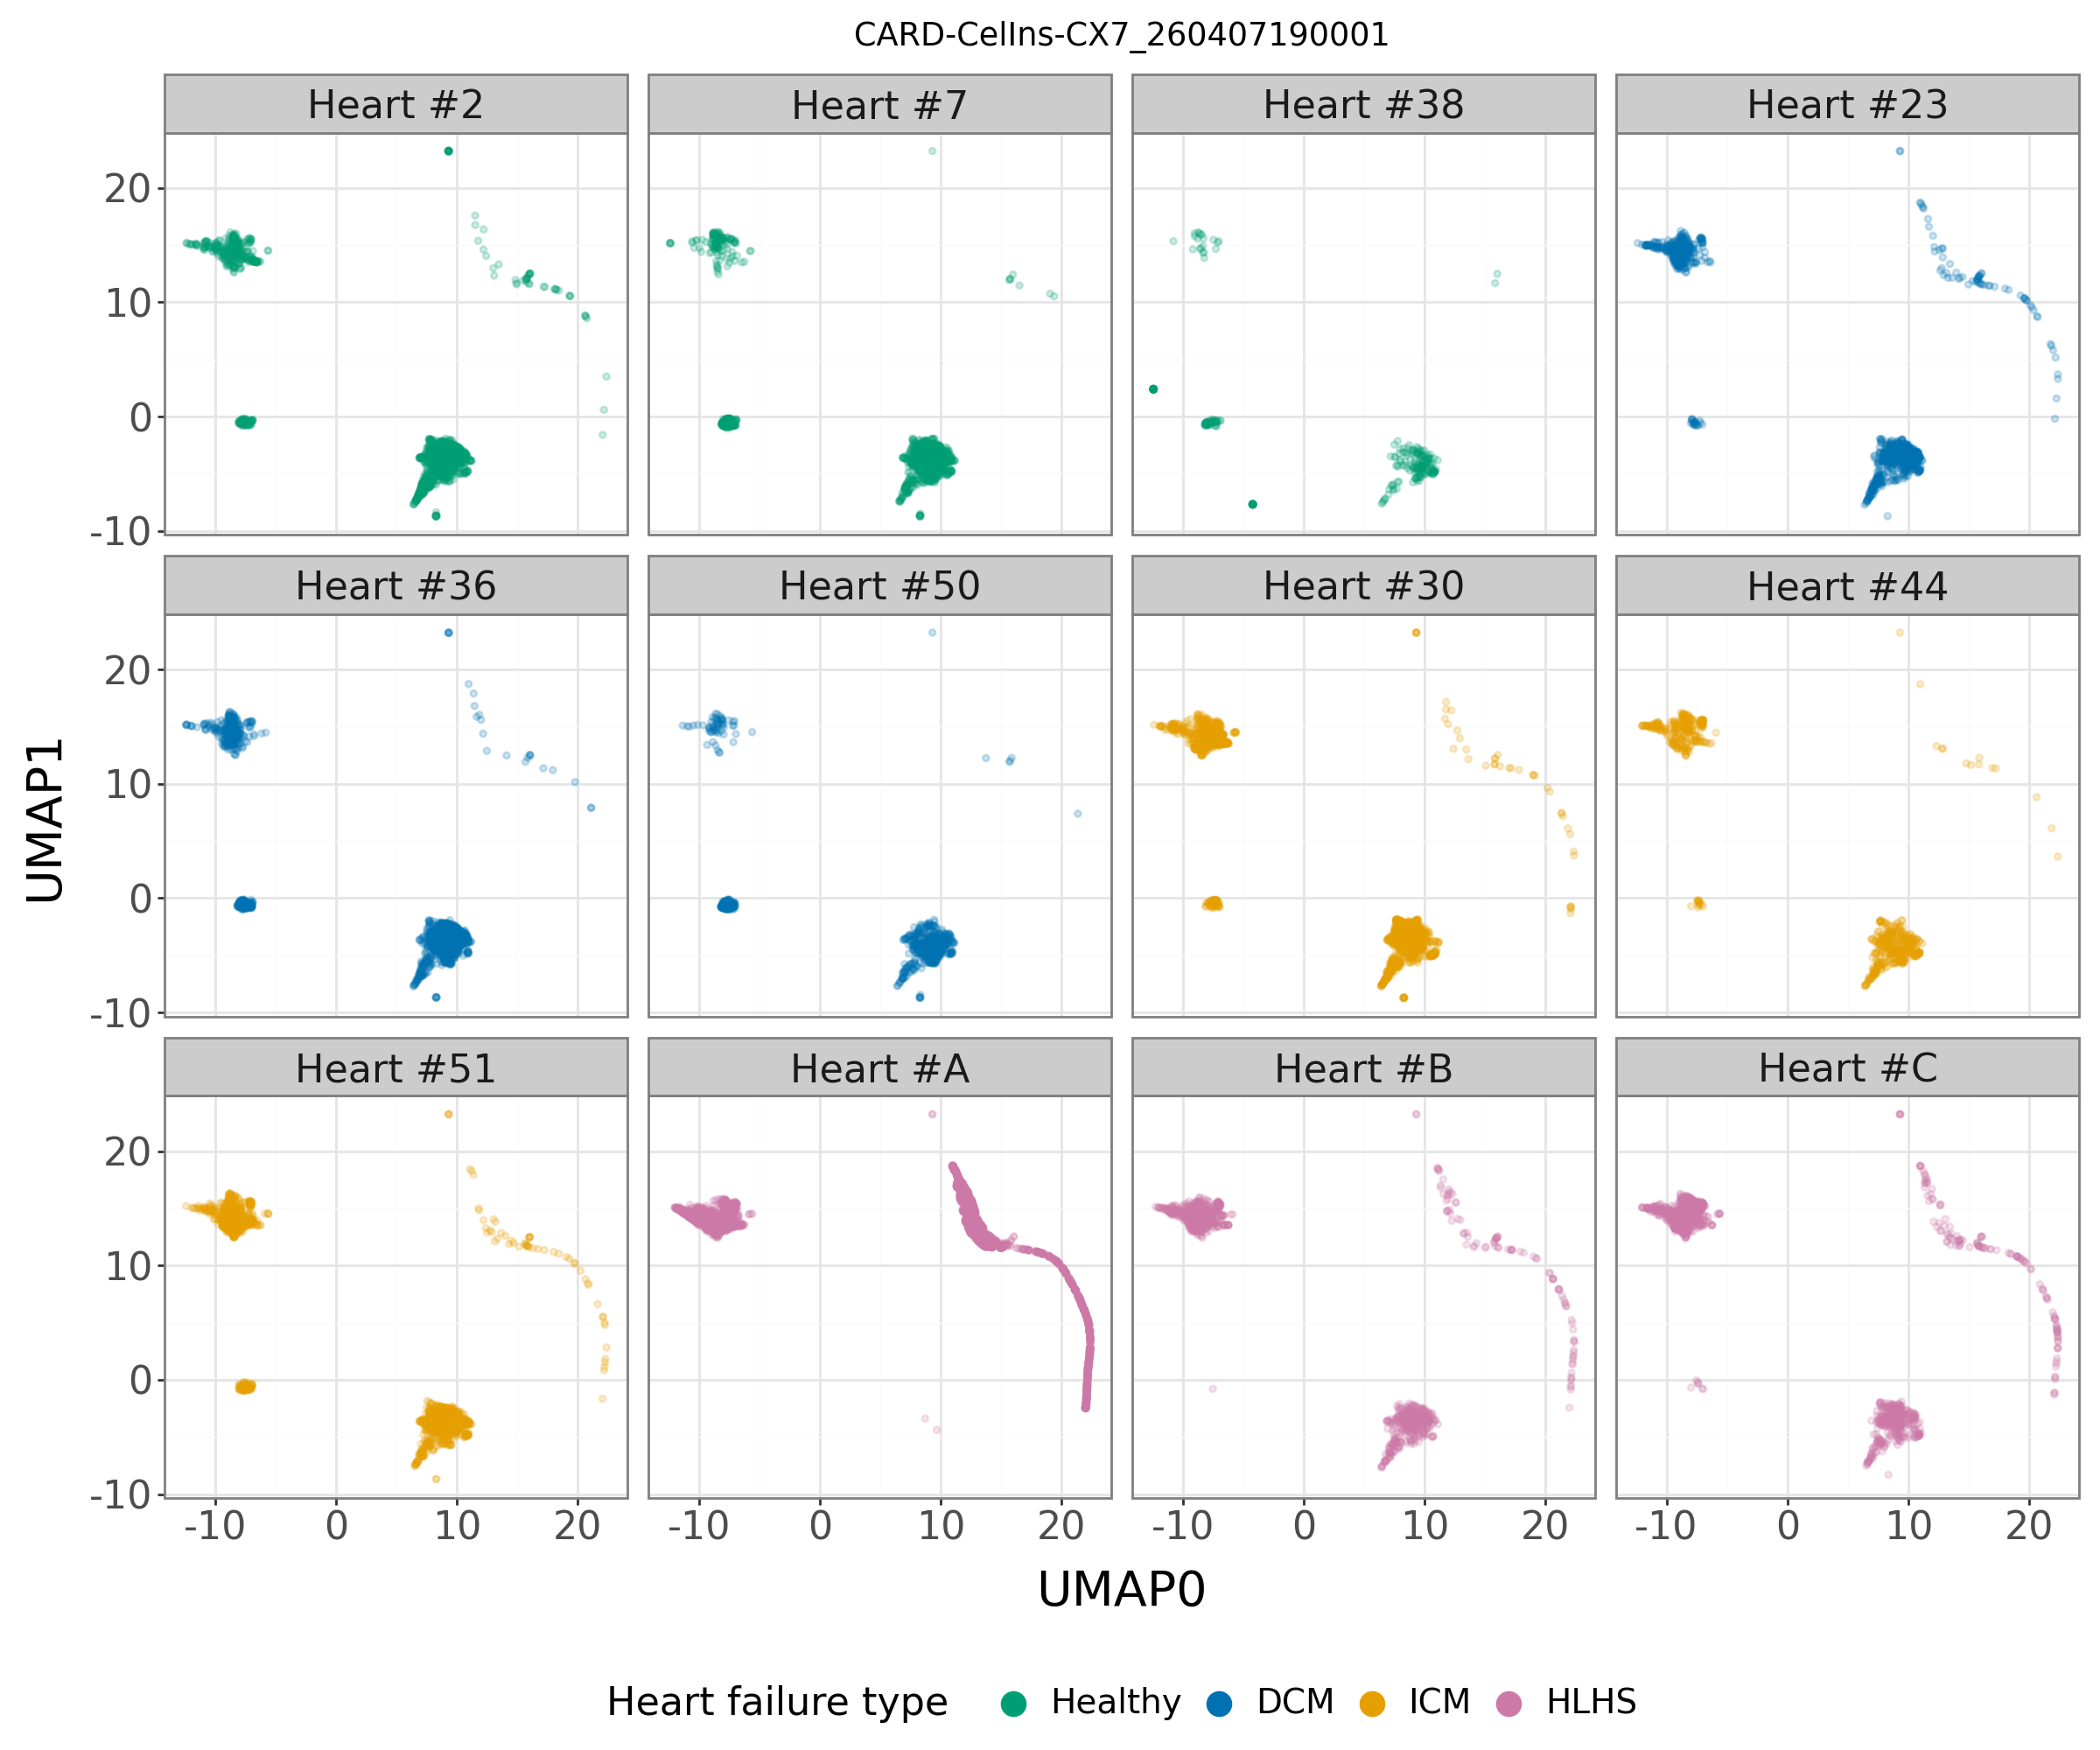

In [12]:
# Set the figure size
height = 10
width = 12
set_option("figure_size", (width, height))

for plate_df in plate_dfs:
    plate = plate_df["Metadata_Plate"].iloc[0]

    # Fit UMAP using all of the feature selected features for this plate
    umap_fit = umap.UMAP(
        random_state=umap_random_seed, n_components=umap_n_components, n_jobs=1
    )
    plate_umap_df = pd.DataFrame(
        umap_fit.fit_transform(plate_df.loc[:, infer_cp_features(plate_df)]),
        columns=[f"UMAP{x}" for x in range(0, umap_n_components)],
        index=plate_df.index,
    )
    print(f"{plate}: {plate_umap_df.shape} UMAP embeddings generated")

    # Add the failure type and heart labels (same ordering as the combined plots)
    plate_umap_df["Metadata_heart_failure_type"] = pd.Categorical(
        plate_df["Metadata_heart_failure_type"].fillna("Healthy"),
        categories=list(failure_type_colors),
        ordered=True,
    )
    plate_umap_df["Metadata_heart_number_label"] = pd.Categorical(
        "Heart #" + plate_df["Metadata_heart_number"].astype(str),
        categories=qc_df["Metadata_heart_number_label"].cat.categories,
        ordered=True,
    )

    # Plot UMAP colored by heart failure type and faceted by heart number
    p = (
        ggplot(
            plate_umap_df,
            aes(x="UMAP0", y="UMAP1", color="Metadata_heart_failure_type"),
        )
        + labs(color="Heart failure type", title=plate)
        + geom_point(alpha=0.2, size=1)
        + facet_wrap("Metadata_heart_number_label", ncol=4, scales="fixed")
        + theme_bw()
        + theme(
            axis_title=element_text(size=20),
            axis_text=element_text(size=16),
            legend_title=element_text(size=16),
            legend_text=element_text(size=14),
            legend_position="bottom",
            strip_text=element_text(size=16),
        )
        + scale_color_manual(values=failure_type_colors)
        + guides(color=guide_legend(override_aes={"alpha": 1, "size": 5}))
    )
    # Save the plot
    p.save(
        per_plate_figure_dir / f"{plate}_facet_umap_by_failure_type.png",
        dpi=600,
        width=width,
        height=height,
    )

    p.show()
